# 110. Balanced Binary Tree
**Difficulty:** 🟢 Easy · **Topic:** Trees · **Pattern:** [DFS Height and Global](README.md) · **LeetCode:** https://leetcode.com/problems/balanced-binary-tree/

## 💡 Concepts

**Core concept(s):** post-order DFS that **returns** a node's height while also **reporting** whether anything below was unbalanced.

**Why it applies here:**
- "Balanced" is checked at every node: `|height(left) - height(right)| <= 1`.
- So every node needs its two children's heights — exactly what a post-order DFS hands back.
- The answer we want (True/False) is different from what the recursion naturally returns (a height).
- Trick: return the height when the subtree is fine, and the **sentinel `-1`** when it is not. One return value carries both facts.

**Key intuition:**
- The naive check asks for heights from the top down, so the same heights get recomputed again and again.
- Asking bottom-up computes each height exactly once, and a `-1` from any child short-circuits straight to the root.

---

### 📚 What is a Binary Tree?
- A **binary tree** is a set of nodes in a branching shape.
- Each node holds a value and up to two children: **left** and **right**.
- The top node is the **root**; nodes with no children are **leaves**.
- **Height** of a node = the number of nodes on the longest path from it down to a leaf (an empty tree has height `0`).
- **In Python:** a small `TreeNode` class with `.val`, `.left`, `.right`.

### 📚 What is DFS (Depth-First Search) / Recursion?
- **DFS** dives down one branch as far as it can, then backs up and tries the next branch.
- It is usually written with **recursion**: a function that calls itself on each child.
- Each pending call waits on the **call stack**, so the stack is as deep as the tree is tall.
- **Complexity:** each node is visited once → **O(n)** time; **O(h)** extra space for the call stack (`h` = height).
- **In Python:** a plain recursive function; `sys.setrecursionlimit` raises the default depth limit (1000) for very tall trees.

### 📚 What is Post-order DFS?
- **Post-order** means: handle the left child, then the right child, and only then the node itself.
- It is the natural order whenever a node's answer depends on its children's answers.
- Mental picture: information flows **bottom-up**, from the leaves to the root.

### 📚 What is a Sentinel Value?
- A **sentinel** is a special value that can never be a real answer, used as a signal.
- Heights are always `>= 0`, so `-1` can safely mean "this subtree is already unbalanced".
- It lets one integer return value carry two pieces of information (height **or** failure) without a global flag.

---

**Prerequisite knowledge:**
- Computing the height (max depth) of a tree recursively — see Maximum Depth of Binary Tree.

## 📝 Problem

Given the root of a binary tree, return `True` if it is **height-balanced**: at **every** node, the heights of the left and right subtrees differ by at most 1.

**Examples**
```
[3,9,20,None,None,15,7]   -> True
[1,2,2,3,3,None,None,4,4] -> False   (at the root: left height 3, right height 1)
[]                        -> True
```

**Constraints:** `0 <= number of nodes <= 5000`, `-10^4 <= Node.val <= 10^4`.

> Two approaches: top-down height recomputation, then one bottom-up DFS with a `-1` sentinel.

In [1]:
from typing import Optional, List
from collections import deque

class TreeNode:
    """A single node of a binary tree: a value plus links to up to two children."""
    def __init__(self, val=0, left=None, right=None):
        self.val = val                     # the number stored at this node
        self.left = left                   # the left child (or None)
        self.right = right                 # the right child (or None)

def build_tree(values):
    """Build a tree from a level-order list, LeetCode style (None = missing child)."""
    if not values or values[0] is None:
        return None
    root = TreeNode(values[0]); q = deque([root]); i = 1
    while q and i < len(values):
        node = q.popleft()                 # the parent we're attaching children to
        if i < len(values):                # attach the left child (if present)
            if values[i] is not None:
                node.left = TreeNode(values[i]); q.append(node.left)
            i += 1
        if i < len(values):                # attach the right child (if present)
            if values[i] is not None:
                node.right = TreeNode(values[i]); q.append(node.right)
            i += 1
    return root

def build_balanced(n):
    """Balanced BST holding 1..n (height ~log n) — used by the benchmark."""
    def helper(lo, hi):
        if lo > hi:
            return None
        mid = (lo + hi) // 2               # middle value becomes the subtree's root
        node = TreeNode(mid)
        node.left = helper(lo, mid - 1)    # smaller values go left
        node.right = helper(mid + 1, hi)   # larger values go right
        return node
    return helper(1, n)

def preorder(root):
    """Collect values in preorder: node, then left, then right."""
    out = []
    def go(n):
        if not n: return
        out.append(n.val); go(n.left); go(n.right)
    go(root); return out

def inorder(root):
    """Collect values in inorder: left, then node, then right (sorted for a BST)."""
    out = []
    def go(n):
        if not n: return
        go(n.left); out.append(n.val); go(n.right)
    go(root); return out

def same_shape(a, b):
    """True if two trees have identical shape and values."""
    if not a and not b: return True        # both empty -> match
    if not a or not b or a.val != b.val: return False  # one empty, or values differ
    return same_shape(a.left, b.left) and same_shape(a.right, b.right)

### Approach 1 — Top-Down: Recompute Height at Every Node (brute force)

**Idea:**
1. Write a plain `height(node)` function.
2. At the root, compare `height(left)` and `height(right)`; if they differ by more than 1, return `False`.
3. Otherwise recurse into the left and right children and check them the same way.
4. Each node's height gets recomputed once for every ancestor above it — that repeated work is the waste.

**Time:** `O(n²)` upper bound — up to `n` nodes each pay an `O(n)` height call. On a balanced tree it is `O(n log n)`: each level's height calls together touch all `n` nodes, and there are `log n` levels.

**Space:** `O(h)` for the recursion stack (`h` = tree height).

In [2]:
def height(node: Optional[TreeNode]) -> int:
    """Number of nodes on the longest downward path from node (0 for an empty tree)."""
    if not node:
        return 0
    return 1 + max(height(node.left), height(node.right))

def is_balanced_brute(root: Optional[TreeNode]) -> bool:
    if not root:
        return True                                    # an empty tree is balanced
    if abs(height(root.left) - height(root.right)) > 1:
        return False                                   # this node breaks the rule
    # This node is fine; now check every node below it the same way.
    # Each recursive call re-measures heights its parent already measured -> repeated work.
    return is_balanced_brute(root.left) and is_balanced_brute(root.right)

### Approach 2 — Bottom-Up DFS with a `-1` Sentinel (optimal)

**Idea:**
1. One post-order DFS `check(node)` returns the node's **height** if its subtree is balanced, or **`-1`** if it is not.
2. Ask the left child first; if it says `-1`, return `-1` at once (no need to look further).
3. Same for the right child.
4. With both heights known, if they differ by more than 1, return `-1`; otherwise return `1 + max(left, right)`.
5. The tree is balanced exactly when `check(root) != -1`.

This is the pattern: the DFS **returns** a height, and the `-1` sentinel **reports** the yes/no answer through the same value.

**Time:** `O(n)` — every node is visited at most once.

**Space:** `O(h)` for the recursion stack.

In [3]:
def is_balanced_optimal(root: Optional[TreeNode]) -> bool:
    def check(node):                       # height of node's subtree, or -1 if it is unbalanced
        if not node:
            return 0                       # empty subtree: height 0, trivially balanced
        left = check(node.left)
        if left == -1:
            return -1                      # left side already failed -> pass the failure straight up
        right = check(node.right)
        if right == -1:
            return -1
        if abs(left - right) > 1:
            return -1                      # this node breaks the rule
        return 1 + max(left, right)        # healthy: hand the parent our real height
    return check(root) != -1

In [4]:
# Correctness check
tests = [
    ([3, 9, 20, None, None, 15, 7], True),
    ([1, 2, 2, 3, 3, None, None, 4, 4], False),
    ([], True),
    ([1], True),
    ([1, 2, 3, 4, None, None, None, 5], False),   # imbalance below the root, at node 2
    ([1, None, 2, None, 3], False),               # a right-leaning chain
    ([1, 2, 2, 3, None, None, 3, 4, None, None, 4], False),
]
for vals, exp in tests:
    root = build_tree(vals)
    a, b = is_balanced_brute(root), is_balanced_optimal(root)
    print(f"{vals} -> brute={a}, optimal={b} | expected={exp}")
    assert a == b == exp, "mismatch!"
print("\nAll tests passed")

[3, 9, 20, None, None, 15, 7] -> brute=True, optimal=True | expected=True
[1, 2, 2, 3, 3, None, None, 4, 4] -> brute=False, optimal=False | expected=False
[] -> brute=True, optimal=True | expected=True
[1] -> brute=True, optimal=True | expected=True
[1, 2, 3, 4, None, None, None, 5] -> brute=False, optimal=False | expected=False
[1, None, 2, None, 3] -> brute=False, optimal=False | expected=False
[1, 2, 2, 3, None, None, 3, 4, None, None, 4] -> brute=False, optimal=False | expected=False

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. We time each approach on trees of growing size `n` and read the **doubling ratio** — how much runtime grows when `n` doubles.

| Theoretical | Ratio when `n` → `2n` |
|-------------|-----------------------|
| `O(n)`        | ≈ **2×** |
| `O(n log n)`  | a bit over **2×** |
| `O(n²)`       | ≈ **4×** |

We use **balanced** trees: the answer is `True`, so neither approach can stop early and every node is checked. On this input the brute force is `O(n log n)` (each of the `log n` levels re-measures all `n` nodes). Its doubling ratio is only slightly above **2×** in theory (about 2.2× at these sizes), so timing noise can hide the difference; what stands out is that the brute force is several times slower than the optimal at every size, because it re-walks every node once per ancestor. The `O(n²)` upper bound is not reached on a balanced tree.


brute   (top-down)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     2000 |       1.47 |           n/a
     4000 |       3.27 |         2.22x
     8000 |       7.21 |         2.21x
    16000 |      16.46 |         2.28x

optimal O(n)      
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     2000 |       0.21 |           n/a
     4000 |       0.41 |         1.96x
     8000 |       0.83 |         2.05x
    16000 |       1.64 |         1.97x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


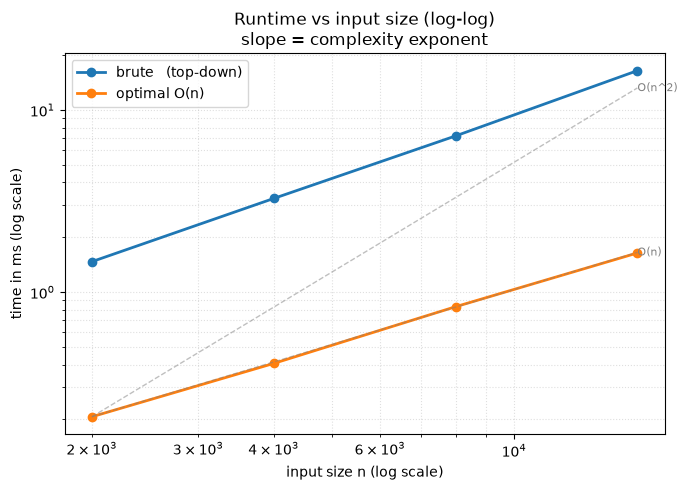

{'brute   (top-down)': [1.469625043682754,
  3.2681659795343876,
  7.206834037788212,
  16.459875041618943],
 'optimal O(n)      ': [0.20662497263401747,
  0.4055839963257313,
  0.8309170370921493,
  1.6401669709011912]}

In [5]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark

def make_worst_case(n):
    return (build_balanced(n),)            # balanced -> no early exit, every node is checked
solutions = {
    "brute   (top-down)": is_balanced_brute,
    "optimal O(n)      ": is_balanced_optimal,
}
sizes = [2000, 4000, 8000, 16000]

benchmark(solutions, make_worst_case, sizes, repeats=3, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [DFS Height and Global](README.md) — the DFS returns each subtree's height, and the sentinel `-1` carries the "unbalanced" answer up through that same return value.
- **Return one thing, signal another:** when the answer (a bool) differs from what the children must hand up (a height), encode failure as an impossible value such as `-1`.
- **Post-order removes repeated work:** measuring heights bottom-up computes each one once (`O(n)`), instead of top-down re-measuring at every ancestor.
- **Short-circuit on the sentinel:** once a child returns `-1`, return `-1` immediately — the rest of the tree cannot change the answer.
- **Signal:** "at every node, compare the left and right subtrees", "height-balanced", "difference in depth".
- **Related problems:** Maximum Depth of Binary Tree, Diameter of Binary Tree, Binary Tree Maximum Path Sum.
- **Common pitfalls:** (1) checking balance only at the root — every node must satisfy the rule; (2) forgetting to propagate `-1` upward, so a parent treats `-1` as a real height; (3) mixing up height in nodes vs. edges (either works if used consistently).